In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Exploratory data analysis
**Goal:** understand the cleaned transaction data before modelling - structure, class imbalance, and which raw attributes relate to fraud.

> All data is synthetic (isolated environment). Patterns are stylised, so conclusions concern the *method*, not real-world prevalence.

In [2]:
df = load_clean()
print(df.shape); df.head()

(59682, 16)


,transaction_id,customer_id,timestamp,amount,merchant_category,channel,device_type,country,home_country,is_new_device,ip_risk_score,velocity_1h,account_age_days,auth_method,is_fraud,fraud_pattern
0,T0000000,C00702,2026-08-11 00:03:35,34.37,groceries,pos,pos_terminal,SG,IN,0,0.2655,0,706,password,0,none
1,T0000001,C01706,2026-08-11 00:05:58,9.45,restaurants,pos,pos_terminal,IN,IN,0,0.0276,0,552,otp,0,none
2,T0000002,C01210,2026-08-11 00:20:51,88.65,digital_goods,web,android,US,US,0,0.0586,0,583,password,0,none
3,T0000003,C01384,2026-08-11 00:25:36,10.38,restaurants,web,android,DE,DE,0,0.3406,0,2498,biometric,0,none
4,T0000004,C04108,2026-08-11 00:25:42,31.67,electronics,mobile_app,android,AE,AE,0,0.1936,0,576,biometric,0,none


In [3]:
df.dtypes.to_frame('dtype').join(df.isna().sum().rename('missing')).T

,transaction_id,customer_id,timestamp,amount,merchant_category,channel,device_type,country,home_country,is_new_device,ip_risk_score,velocity_1h,account_age_days,auth_method,is_fraud,fraud_pattern
dtype,str,str,datetime64[us],float64,str,str,str,str,str,int64,float64,int64,int64,str,int64,str
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Class imbalance
Fraud is rare, therefore accuracy is misleading; the project reports precision, recall, F1, ROC-AUC, PR-AUC and false-positive rate.

In [4]:
vc = df.is_fraud.value_counts(); print(vc.to_dict(), f'fraud rate = {df.is_fraud.mean():.3%}')
print('A model that predicts "legit" always has accuracy', round(1-df.is_fraud.mean(), 4))

{0: 58476, 1: 1206} fraud rate = 2.021%
A model that predicts "legit" always has accuracy 0.9798


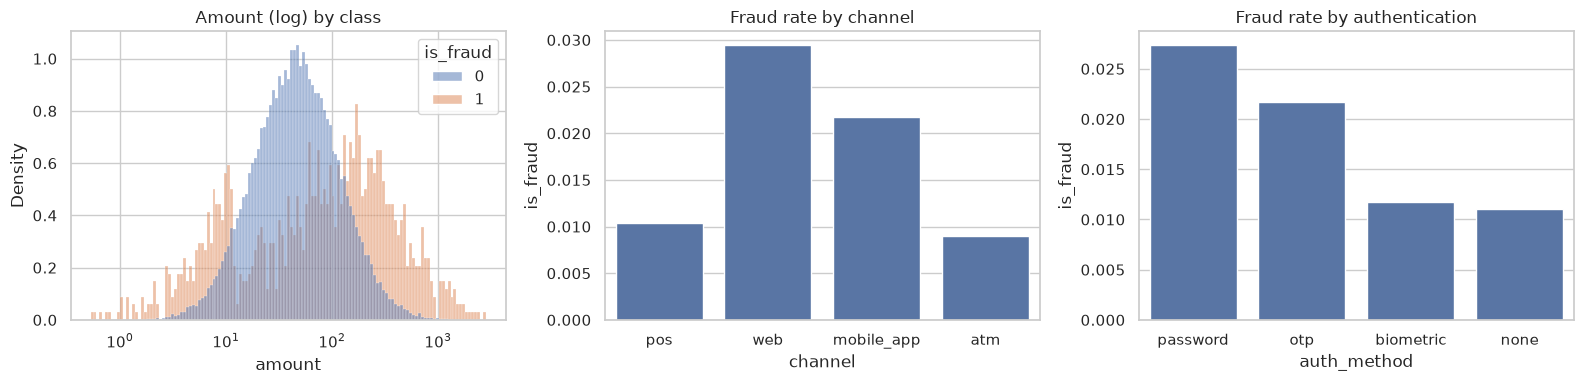

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df, x='amount', hue='is_fraud', log_scale=True, stat='density', common_norm=False, ax=ax[0]); ax[0].set_title('Amount (log) by class')
sns.barplot(data=df, x='channel', y='is_fraud', ax=ax[1], errorbar=None); ax[1].set_title('Fraud rate by channel')
sns.barplot(data=df, x='auth_method', y='is_fraud', ax=ax[2], errorbar=None); ax[2].set_title('Fraud rate by authentication')
plt.tight_layout()

In [6]:
num = ['amount','ip_risk_score','velocity_1h','account_age_days','is_new_device']
df[num].corrwith(df.is_fraud, method='spearman').sort_values().to_frame('spearman vs is_fraud')

,spearman vs is_fraud
account_age_days,-0.029934
amount,0.048617
velocity_1h,0.105363
ip_risk_score,0.122521
is_new_device,0.202402


In [7]:
px.scatter(df.sample(5000, random_state=1), x='ip_risk_score', y='amount', color=df.sample(5000, random_state=1).is_fraud.astype(str), log_y=True, opacity=.6, title='IP risk vs amount (5k sample)')

**Take-aways** - fraud concentrates in high IP-risk, new-device, high-velocity and unusual-hour activity; no single raw attribute separates the classes, motivating engineered features (notebook 02) and ensemble models (03, 06).